In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             roc_auc_score, average_precision_score)

dados = pd.read_csv("../data/processed/clientes.csv")
y = dados["churn"]
# TotalCharges ≈ tenure × MonthlyCharges: é redundante e confunde a interpretação, então fica de fora
X = dados.drop(columns=["customerID", "churn", "TotalCharges"])

numericas = ["tenure", "MonthlyCharges"]
categoricas = [c for c in X.columns if c not in numericas]

# 75% treino, 25% teste, mantendo a mesma proporção de churn nos dois (stratify)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

preparo = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categoricas),
])
modelos = {
    "Regressão logística": Pipeline([("prep", preparo), ("modelo", LogisticRegression(max_iter=2000))]),
    "Logística com peso (balanced)": Pipeline([("prep", preparo),
        ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Gradient boosting": Pipeline([("prep", preparo), ("modelo", HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40, random_state=42))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
linhas, probs = [], {}
for nome, modelo in modelos.items():
    auc_cv = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="roc_auc").mean()
    modelo.fit(X_treino, y_treino)
    p = modelo.predict_proba(X_teste)[:, 1]
    probs[nome] = p
    prev = (p >= 0.5).astype(int)
    linhas.append({"modelo": nome,
                   "acurácia": accuracy_score(y_teste, prev),
                   "recall": recall_score(y_teste, prev),
                   "precisão": precision_score(y_teste, prev),
                   "ROC-AUC": roc_auc_score(y_teste, p),
                   "PR-AUC": average_precision_score(y_teste, p),
                   "ROC-AUC (validação cruzada)": auc_cv})

print(f"Referência: dizer que NINGUÉM cancela já dá {1 - y_teste.mean():.1%} de acurácia\n")
pd.DataFrame(linhas).set_index("modelo").round(3)

Referência: dizer que NINGUÉM cancela já dá 73.5% de acurácia



,acurácia,recall,precisão,ROC-AUC,PR-AUC,ROC-AUC (validação cruzada)
modelo,,,,,,
Regressão logística,0.801,0.548,0.646,0.845,0.634,0.843
Logística com peso (balanced),0.754,0.790,0.524,0.844,0.632,0.842
Gradient boosting,0.799,0.505,0.657,0.841,0.646,0.840


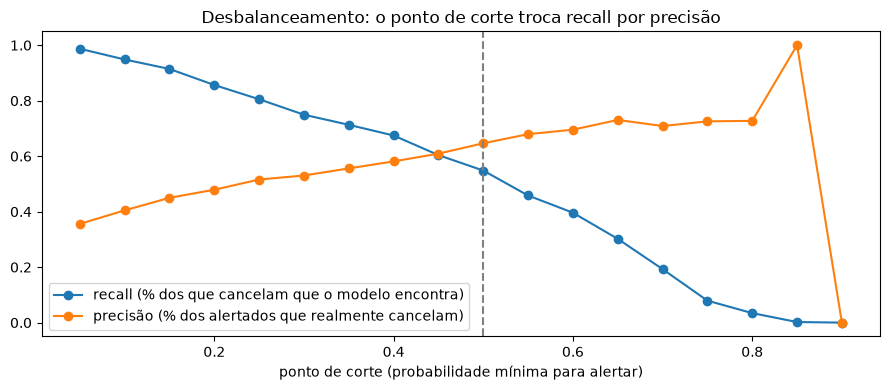

In [2]:
# Como o ponto de corte muda o resultado (regressão logística)
p = probs["Regressão logística"]
cortes = np.arange(0.05, 0.91, 0.05)
rec = [recall_score(y_teste, p >= c) for c in cortes]
prec = [precision_score(y_teste, p >= c, zero_division=0) for c in cortes]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(cortes, rec, marker="o", label="recall (% dos que cancelam que o modelo encontra)")
ax.plot(cortes, prec, marker="o", label="precisão (% dos alertados que realmente cancelam)")
ax.axvline(0.5, color="gray", ls="--")
ax.set_xlabel("ponto de corte (probabilidade mínima para alertar)")
ax.set_title("Desbalanceamento: o ponto de corte troca recall por precisão")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/corte_recall_precisao.png", dpi=120)
plt.show()

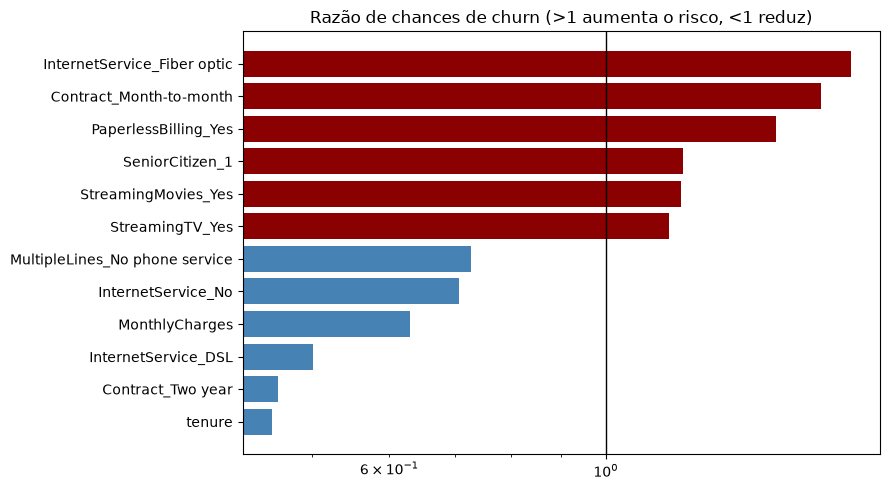

num__tenure                            0.45
cat__Contract_Two year                 0.46
cat__InternetService_DSL               0.50
num__MonthlyCharges                    0.63
cat__InternetService_No                0.71
cat__MultipleLines_No phone service    0.73
cat__StreamingTV_Yes                   1.16
cat__StreamingMovies_Yes               1.19
cat__SeniorCitizen_1                   1.20
cat__PaperlessBilling_Yes              1.49
cat__Contract_Month-to-month           1.66
cat__InternetService_Fiber optic       1.78
dtype: float64

In [3]:
# O que aumenta (ou reduz) o risco de churn: razão de chances da regressão logística
logistica = modelos["Regressão logística"]
nomes = logistica.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logistica.named_steps["modelo"].coef_[0], index=nomes)
razao = np.exp(coef).sort_values()
razao = razao[~razao.index.str.contains("No internet service")]  # repete a informação "sem internet"
destaque = pd.concat([razao.head(6), razao.tail(6)])

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([n.split("__")[1] for n in destaque.index], destaque,
        color=["steelblue" if r < 1 else "darkred" for r in destaque])
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_title("Razão de chances de churn (>1 aumenta o risco, <1 reduz)")
plt.tight_layout()
plt.savefig("../reports/figures/fatores_risco.png", dpi=120)
plt.show()

destaque.round(2)

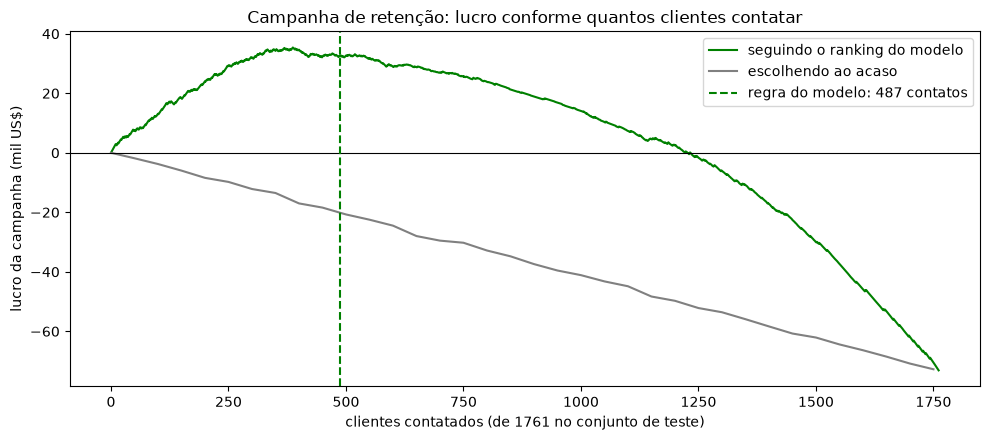

Premissas: contato US$ 10, desconto de 2 mensalidades, cliente retido vale 12 mensalidades, 30% dos que iam cancelar aceitam ficar
Clientes que cancelariam entre os contatados: 291 de 467


Contatar todos                          -73121.0
Contatar 487 aleatórios                 -20225.0
Contatar os 487 indicados pelo modelo    32599.0
dtype: float64

In [4]:
from src.financeiro import lucro_real, lucro_esperado, CUSTO_CONTATO, MESES_DESCONTO, MESES_VALOR, TAXA_RETENCAO

mensal = X_teste["MonthlyCharges"].values
real = y_teste.values
n = len(real)

# Lucro esperado de contatar cada cliente, com a probabilidade do modelo
esperado = lucro_esperado(p, mensal)
ordem = np.argsort(-esperado)  # do cliente mais "lucrativo" de contatar para o menos

curva = [lucro_real(np.isin(np.arange(n), ordem[:k]), real, mensal) for k in range(n + 1)]
rng = np.random.default_rng(42)
aleatorio = [np.mean([lucro_real(np.isin(np.arange(n), rng.choice(n, k, replace=False)), real, mensal)
                      for _ in range(30)]) for k in range(0, n + 1, 50)]

contatar = esperado > 0  # regra do modelo: contatar quem tem lucro esperado positivo
resumo = pd.Series({
    "Contatar todos": lucro_real(np.ones(n, bool), real, mensal),
    f"Contatar {contatar.sum()} aleatórios": np.mean([lucro_real(np.isin(np.arange(n),
        rng.choice(n, contatar.sum(), replace=False)), real, mensal) for _ in range(200)]),
    f"Contatar os {contatar.sum()} indicados pelo modelo": lucro_real(contatar, real, mensal),
})

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(range(n + 1), np.array(curva) / 1000, color="green", label="seguindo o ranking do modelo")
ax.plot(range(0, n + 1, 50), np.array(aleatorio) / 1000, color="gray", label="escolhendo ao acaso")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(contatar.sum(), color="green", ls="--", label=f"regra do modelo: {contatar.sum()} contatos")
ax.set_xlabel(f"clientes contatados (de {n} no conjunto de teste)")
ax.set_ylabel("lucro da campanha (mil US$)")
ax.set_title("Campanha de retenção: lucro conforme quantos clientes contatar")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/lucro_campanha.png", dpi=120)
plt.show()

print(f"Premissas: contato US$ {CUSTO_CONTATO}, desconto de {MESES_DESCONTO} mensalidades, "
      f"cliente retido vale {MESES_VALOR} mensalidades, {TAXA_RETENCAO:.0%} dos que iam cancelar aceitam ficar")
print(f"Clientes que cancelariam entre os contatados: {real[contatar].sum()} de {real.sum()}")
resumo.round(0)

In [5]:
# E se as premissas mudarem? (a mais incerta é a taxa de retenção da oferta)
linhas = []
for taxa in [0.15, 0.30, 0.45]:
    e = lucro_esperado(p, mensal, taxa=taxa)
    linhas.append({"taxa de retenção": f"{taxa:.0%}",
                   "clientes contatados": int((e > 0).sum()),
                   "lucro com o modelo (US$)": lucro_real(e > 0, real, mensal, taxa=taxa),
                   "lucro contatando todos (US$)": lucro_real(np.ones(n, bool), real, mensal, taxa=taxa)})
pd.DataFrame(linhas).set_index("taxa de retenção").round(0)

,clientes contatados,lucro com o modelo (US$),lucro contatando todos (US$)
taxa de retenção,,,
15%,256,6379.0,-124594.0
30%,487,32599.0,-73121.0
45%,613,67757.0,-21648.0
